# So 4 model do do sau

Bon model:

| Ten trong bang | Ban chat | Weight |
|---|---|---|
| DepthART MobileNetV4-S | mang nho, chay bien | da co trong may |
| DepthART MNV4-M-slim-SPF | cung ho, phan giai ma mong hon | chua co, o 3 tai ve o D (~25 MB) |
| YOLO26n-depth | ban nhe cua YOLO26, doan ra met | chua cai `ultralytics`, o 3 tai `yolo26n-depth.pt` ve o D |
| Depth Anything V2 Small | ban manh nhat trong bang NYUD | tai tu Hugging Face luc chay |

## Cach dung

1. Chay o 1, o 2.
2. O 3 tai nhung gi con thieu. Bo qua neu khong co mang.
3. O 4 mac dinh **tat**. Doi `RUN = True` roi chay. Moi model vai phut. Dong Chrome truoc.
4. O 5 ve bieu do tu file CSV vua ghi.

Moi model ghi mot thu muc `D:\replica_sim\results\cmp_<ten>`. Chua chay thi thu muc do khong co, va **khong co so de bao cao**.

Ca 4 model deu la doan **tuong doi** (khong ra met that neu khong co dap an).
O 4 can cung mot kieu: `met = scale * du_doan + shift` tren ca anh, giong `run_eval.py`.
Khong dao 1/do_sau truoc — phep can tu tim chieu dung. Neu scale ra am, o 4 in canh bao.


In [1]:
# O 1 — duong dan
from pathlib import Path
import sys

CANDIDATES = [
    Path.cwd(),
    Path.cwd() / "models" / "Depth3D_Localizer" / "simulation",
    Path(r"D:\Tài liệu lab HMI\FireGrounder-V3\models\Depth3D_Localizer\simulation"),
]
SIM = next((p for p in CANDIDATES if (p / "utils.py").is_file()), None)
if SIM is None:
    raise SystemExit("Khong thay thu muc simulation. Mo notebook tu repo FireGrounder-V3.")
PARENT = SIM.parent
for p in (str(SIM), str(PARENT)):
    if p not in sys.path:
        sys.path.insert(0, p)

SAMPLES = Path(r"D:\replica_sim\samples")
RESULTS = Path(r"D:\replica_sim\results")
WEIGHTS = Path(r"D:\replica_sim\weights")
WEIGHTS.mkdir(parents=True, exist_ok=True)
DEPTHART = PARENT / "DepthART"
CKPT = DEPTHART / "checkpoints" / "relative"

print("simulation :", SIM)
print("samples    :", SAMPLES, "co" if SAMPLES.is_dir() else "KHONG CO")
print("weights    :", WEIGHTS)
print("slim ckpt  :", CKPT / "depthart_relative_mnv4m_slim_224.pth")


simulation : d:\Tài liệu lab HMI\FireGrounder-V3\models\Depth3D_Localizer\simulation
samples    : D:\replica_sim\samples co
weights    : D:\replica_sim\weights
slim ckpt  : d:\Tài liệu lab HMI\FireGrounder-V3\models\Depth3D_Localizer\DepthART\checkpoints\relative\depthart_relative_mnv4m_slim_224.pth


## O 2 — bon cach do

Moi ham nhan duong anh, tra ve bang so **dung kich thuoc anh goc**, chua can.

- DepthART va Depth Anything: gia tri cao thuong la **gan**. Khong sao — o 4 can affine, scale am nghia la model dang de cao = gan.
- YOLO26n-depth: `result.depth.data`. Tai lieu Ultralytics noi don vi met, nhung head that la log-depth va scale tuyet doi tach roi. Van can cung kieu, de so cong bang. Khong goi day la met that.

Ham nao khong nap duoc thi o 4 bo qua model do va in loi. Khong dien so gia.


In [3]:
# O 2 — dinh nghia 4 model
import numpy as np
from PIL import Image

def _as_map(d):
    d = np.asarray(d, dtype=np.float32)
    d = np.squeeze(d)
    if d.ndim != 2:
        raise RuntimeError(f"depth shape {d.shape}, can (H, W)")
    return d

class MNV4S:
    name = "mnv4s"
    label = "DepthART MNV4-S"
    def load(self):
        from depth_model import DepthBackend
        self.b = DepthBackend(prefer="depthart", depthart_encoder="MNV4-S")
        self.b.load()
        print("  nap", self.b.model_name)
    def predict(self, path):
        return _as_map(self.b.infer_path(path))

class MNV4Slim:
    name = "mnv4m_slim"
    label = "DepthART MNV4-M-slim-SPF"
    def load(self):
        ck = CKPT / "depthart_relative_mnv4m_slim_224.pth"
        if not ck.is_file():
            raise FileNotFoundError(
                "Chua co weight slim. Chay o 3 truoc.\n  " + str(ck))
        from depth_model import DepthBackend
        self.b = DepthBackend(prefer="depthart", depthart_encoder="MNV4-M-SLIM-SPF",
                              depthart_checkpoint=ck)
        self.b.load()
        print("  nap", self.b.model_name)
    def predict(self, path):
        return _as_map(self.b.infer_path(path))

class Yolo26N:
    name = "yolo26n"
    label = "YOLO26n-depth"
    def load(self):
        try:
            from ultralytics import YOLO
        except ImportError as e:
            raise ImportError("Chua cai ultralytics. Chay o 3.") from e
        pt = WEIGHTS / "yolo26n-depth.pt"
        self.model = YOLO(str(pt if pt.is_file() else "yolo26n-depth.pt"))
        print("  nap", getattr(self.model, "model_name", None) or "yolo26n-depth")
    def predict(self, path):
        r = self.model(str(path), verbose=False)[0]
        depth = getattr(r, "depth", None)
        if depth is None or getattr(depth, "data", None) is None:
            raise RuntimeError("Ket qua YOLO khong co result.depth. "
                               "Ban ultralytics nay co the chua ho tro task depth.")
        return _as_map(depth.data.detach().cpu().numpy())

class DAV2:
    name = "dav2s"
    label = "Depth Anything V2 Small"
    def load(self):
        from depth_model import DepthBackend
        self.b = DepthBackend(prefer="dav2")
        self.b.load()
        print("  nap", self.b.model_name)
    def predict(self, path):
        return _as_map(self.b.infer_path(path))

MODELS = [MNV4S(), MNV4Slim(), Yolo26N(), DAV2()]
print("4 model:", [m.label for m in MODELS])


4 model: ['DepthART MNV4-S', 'DepthART MNV4-M-slim-SPF', 'YOLO26n-depth', 'Depth Anything V2 Small']


## O 3 — tai phan con thieu

Chi tai khi file chua co. Luu vao `D:\replica_sim\weights` va vao thu muc checkpoint DepthART tren o D.
Khong co mang thi o nay bao loi tung mon, khong dung ca notebook.


In [4]:
# O 3 — tai weight con thieu
DOWNLOAD_SLIM = True
DOWNLOAD_YOLO = True

slim = CKPT / "depthart_relative_mnv4m_slim_224.pth"
if not DOWNLOAD_SLIM:
    print("bo qua slim")
elif slim.is_file():
    print("slim da co:", slim, f"({slim.stat().st_size/1e6:.1f} MB)")
else:
    from huggingface_hub import hf_hub_download
    print("tai slim ve", slim)
    hf_hub_download(repo_id="Fengxue93/DepthART",
                    filename="relative/depthart_relative_mnv4m_slim_224.pth",
                    local_dir=str(DEPTHART / "checkpoints"))
    print("xong" if slim.is_file() else "TAI XONG NHUNG KHONG THAY FILE")

pt = WEIGHTS / "yolo26n-depth.pt"
if not DOWNLOAD_YOLO:
    print("bo qua YOLO")
else:
    try:
        import ultralytics
        print("ultralytics", ultralytics.__version__)
    except ImportError:
        import subprocess, sys as _sys
        print("cai ultralytics (goi pip, mat vai phut)...")
        subprocess.check_call([_sys.executable, "-m", "pip", "install", "-q", "ultralytics>=8.3.0"])
        import ultralytics
        print("da cai", ultralytics.__version__)
    if pt.is_file():
        print("yolo26n-depth.pt da co:", f"{pt.stat().st_size/1e6:.1f} MB")
    else:
        from ultralytics import YOLO
        print("tai yolo26n-depth.pt (Ultralytics tu tai, roi copy ve o D)")
        m = YOLO("yolo26n-depth.pt")
        src = Path(getattr(m, "ckpt_path", "") or "")
        if not src.is_file():
            cands = list(Path.cwd().glob("yolo26n-depth.pt"))
            src = cands[0] if cands else src
        if src.is_file() and src.resolve() != pt.resolve():
            import shutil
            shutil.copy2(src, pt)
        print("weight YOLO:", pt if pt.is_file() else src)


tai slim ve d:\Tài liệu lab HMI\FireGrounder-V3\models\Depth3D_Localizer\DepthART\checkpoints\relative\depthart_relative_mnv4m_slim_224.pth


relative/depthart_relative_mnv4m_slim_22(…): reconstructing file:   0%|          |  0.00B / 24.7MB            

relative/depthart_relative_mnv4m_slim_22(…): downloading bytes:           |  0.00B            

xong
cai ultralytics (goi pip, mat vai phut)...
Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\ThinkPad\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
da cai 8.4.174
tai yolo26n-depth.pt (Ultralytics tu tai, roi copy ve o D)
weight YOLO: D:\replica_sim\weights\yolo26n-depth.pt


## O 4 — cham

Mac dinh tat. Moi anh: model doan mot bang, can scale+shift cho khop GT **ca anh**, roi lay dung cac diem da chon trong `samples/` de tinh sai so.

`LIMIT_SAMPLES = 40` de thu nhanh. `None` de cham ca 400 diem — moi model khoang vai phut, YOLO26 va V2 co the lau hon.

Ket qua ghi `results/cmp_<ten>/per_sample.csv`. Cot `err` la sai so vi tri 3D (met). Cot `depth_err` la sai so khoang cach (met).


In [10]:
# O 4 — cham (tat mac dinh)
RUN = True
LIMIT_SAMPLES = None      # None = ca 400 diem
WHICH = None            # None = ca 4. Hoac ["mnv4s", "dav2s"]

import json, csv, time
from utils import (load_depth_map, align_scale_shift, pixel_to_cam,
                   cam_to_world)

if not RUN:
    print("Dang tat. Doi RUN = True roi chay lai o nay.")
else:
    files = sorted(SAMPLES.glob("*.json"))
    if LIMIT_SAMPLES:
        files = files[:LIMIT_SAMPLES]
    if not files:
        raise SystemExit("Khong co sample JSON trong " + str(SAMPLES))
    samples = [json.loads(p.read_text(encoding="utf-8")) for p in files]
    chosen = [m for m in MODELS if WHICH is None or m.name in WHICH]
    print(f"{len(samples)} diem, {len({s['frame_path'] for s in samples})} anh")

    for model in chosen:
        print("\n===", model.label, "===")
        try:
            model.load()
        except Exception as e:
            print(f"  BO QUA — khong nap duoc: {type(e).__name__}: {e}")
            continue
        out_dir = RESULTS / f"cmp_{model.name}"
        out_dir.mkdir(parents=True, exist_ok=True)
        cache = {}
        scales = []
        rows = []
        t0 = time.perf_counter()
        for s in samples:
            key = s["frame_path"]
            if key not in cache:
                try:
                    gt = load_depth_map(s["depth_path"], scale=s["depth_scale"])
                    pred = np.asarray(model.predict(key), dtype=np.float32)
                except Exception as e:
                    print(f"  BO QUA anh {key}: {type(e).__name__}: {e}")
                    continue
                if pred.shape != gt.shape:
                    print(f"  BO QUA — depth {pred.shape} khac anh {gt.shape}")
                    continue
                ss = align_scale_shift(pred, gt)
                scales.append(ss.scale)
                aligned = ss.scale * pred + ss.shift
                aligned = np.where(np.isfinite(aligned), aligned, np.nan)
                cache[key] = aligned
            u, v = s["pixel"]
            d = float(cache[key][v, u])
            if not np.isfinite(d) or d <= 0:
                continue
            intr = s["intrinsics"]
            cam = pixel_to_cam((u, v), d, intr)
            R = np.asarray(s["pose"]["R"], dtype=float)
            t = np.asarray(s["pose"]["t"], dtype=float)
            world = cam_to_world(cam, R, t)
            gt_w = np.asarray(s["xyz_gt_world"], dtype=float)
            diff = world - gt_w
            rows.append({
                "sample_id": s["sample_id"], "scene": s["scene"],
                "frame": s["frame"], "region": s["region"],
                "depth_gt": s["depth_gt_m"], "depth_pred": d,
                "depth_err": d - s["depth_gt_m"],
                "err": float(np.linalg.norm(diff)),
                "err_x": float(diff[0]), "err_y": float(diff[1]), "err_z": float(diff[2]),
            })
        if not rows:
            print("  BO QUA — khong con diem hop le sau khi can.")
            continue
        if scales and float(np.median(scales)) < 0:
            print(f"  scale trung vi {float(np.median(scales)):.4f} < 0: "
                  "model de gia tri cao = gan. Phep can da dao chieu, so van dung.")
        csv_path = out_dir / "per_sample.csv"
        with csv_path.open("w", newline="", encoding="utf-8") as fh:
            w = csv.DictWriter(fh, fieldnames=list(rows[0]))
            w.writeheader()
            w.writerows(rows)
        err = np.array([r["err"] for r in rows])
        de = np.abs([r["depth_err"] for r in rows])
        print(f"  {len(rows)} diem, {time.perf_counter()-t0:.0f}s")
        print(f"  MAE vi tri  {err.mean():.3f} m   median {np.median(err):.3f} m")
        print(f"  MAE do sau  {de.mean():.3f} m")
        print("  ghi", csv_path)


400 diem, 86 anh

=== DepthART MNV4-S ===
[DepthBackend] Loaded: DepthART-MNV4-S @ 224px  [CPU]  (cpu)
  nap DepthART-MNV4-S @ 224px  [CPU]
  scale trung vi -0.0003 < 0: model de gia tri cao = gan. Phep can da dao chieu, so van dung.
  400 diem, 12s
  MAE vi tri  0.301 m   median 0.237 m
  MAE do sau  0.273 m
  ghi D:\replica_sim\results\cmp_mnv4s\per_sample.csv

=== DepthART MNV4-M-slim-SPF ===
[DepthBackend] Loaded: DepthART-MNV4-M-SLIM-SPF @ 224px  [CPU]  (cpu)
  nap DepthART-MNV4-M-SLIM-SPF @ 224px  [CPU]
  scale trung vi -0.6793 < 0: model de gia tri cao = gan. Phep can da dao chieu, so van dung.
  400 diem, 14s
  MAE vi tri  0.284 m   median 0.225 m
  MAE do sau  0.259 m
  ghi D:\replica_sim\results\cmp_mnv4m_slim\per_sample.csv

=== YOLO26n-depth ===
  nap D:\replica_sim\weights\yolo26n-depth.pt
  400 diem, 26s
  MAE vi tri  0.353 m   median 0.266 m
  MAE do sau  0.316 m
  ghi D:\replica_sim\results\cmp_yolo26n\per_sample.csv

=== Depth Anything V2 Small ===


Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

[DepthBackend] Loaded: Depth-Anything-V2-Small [fallback]  (cpu)
  nap Depth-Anything-V2-Small [fallback]
  scale trung vi -0.5400 < 0: model de gia tri cao = gan. Phep can da dao chieu, so van dung.
  400 diem, 153s
  MAE vi tri  0.226 m   median 0.170 m
  MAE do sau  0.204 m
  ghi D:\replica_sim\results\cmp_dav2s\per_sample.csv


## O 5 — bang va bieu do

Doc moi thu muc `cmp_*` da co. Thu muc chua chay thi khong xuat hien — dung, khong phai loi.


,n,MAE_vi_tri_m,Median_m,P95_m,duoi_25cm,MAE_do_sau_m
model,,,,,,
Depth Anything V2-S,400,0.2260,0.1695,0.5803,0.6500,0.2041
DepthART MNV4-M-slim,400,0.2842,0.2248,0.7084,0.5375,0.2588
DepthART MNV4-S,400,0.3012,0.2374,0.7787,0.5225,0.2728
YOLO26n-depth,400,0.3534,0.2660,0.8842,0.4750,0.3158


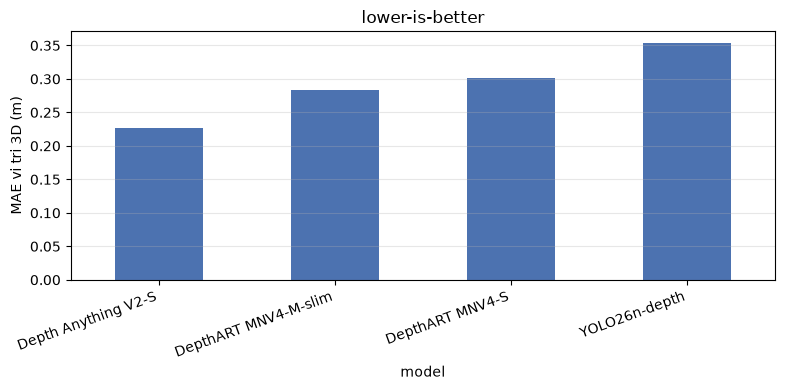

Luu y: moi hang phai cung mot bo diem (cot n giong nhau) thi moi so duoc.
Neu n khac nhau, model do bi bo bot diem — dung so sanh truc tiep.


In [11]:
# O 5 — doc ket qua va ve
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

LABEL = {
    "mnv4s": "DepthART MNV4-S",
    "mnv4m_slim": "DepthART MNV4-M-slim",
    "yolo26n": "YOLO26n-depth",
    "dav2s": "Depth Anything V2-S",
}
rows = []
frames = {}
for d in sorted(RESULTS.glob("cmp_*")):
    csv_path = d / "per_sample.csv"
    if not csv_path.is_file():
        continue
    df = pd.read_csv(csv_path)
    key = d.name.replace("cmp_", "")
    rows.append({
        "model": LABEL.get(key, key),
        "n": len(df),
        "MAE_vi_tri_m": df["err"].mean(),
        "Median_m": df["err"].median(),
        "P95_m": df["err"].quantile(0.95),
        "duoi_25cm": (df["err"] < 0.25).mean(),
        "MAE_do_sau_m": df["depth_err"].abs().mean(),
    })
    frames[LABEL.get(key, key)] = df

if not rows:
    print("Chua co ket qua nao. Bat RUN = True o o 4 roi chay.")
else:
    bang = pd.DataFrame(rows).set_index("model").round(4)
    display(bang)
    fig, ax = plt.subplots(figsize=(8, 4))
    bang["MAE_vi_tri_m"].plot(kind="bar", ax=ax, color="#4C72B0")
    ax.set_ylabel("MAE vi tri 3D (m)")
    ax.set_title("lower-is-better")
    ax.grid(axis="y", alpha=0.3)
    plt.xticks(rotation=20, ha="right")
    fig.tight_layout()
    plt.show()
    print("Luu y: moi hang phai cung mot bo diem (cot n giong nhau) thi moi so duoc.")
    print("Neu n khac nhau, model do bi bo bot diem — dung so sanh truc tiep.")
